# snow Tutorial 8 - Chirped and Apodized Poling

A uniform grating phase matches one $\Delta k$. If the poling period changes along the waveguide, different positions phase match different wavelengths, and the device converts a broader band. This notebook builds chirped and apodized gratings with explicit poling functions and checks the simulations against the grating's Fourier transform.

Explicit poling is slower than the `Kg` model (about half a minute per run here), so this notebook takes about two minutes to run.

We start with the usual imports and definitions.

In [1]:
import numpy as np
from numpy.fft import fft, ifft, fftshift, fftfreq
import matplotlib.pyplot as plt

import os, sys
sys.path.insert(0, os.path.abspath('..'))  # use this repo's snow package
import snow.pulses as pulses
import snow.materials as materials
import snow.waveguides as waveguides

from scipy.constants import pi, c, epsilon_0
nm = 1e-9
um = 1e-6
mm = 1e-3
ps = 1e-12
fs = 1e-15
MHz = 1e6
GHz = 1e9
THz = 1e12
pJ = 1e-12
fJ = 1e-15
mW = 1e-3
uW = 1e-6

#Larger font for plots
plt.rcParams.update({'font.size': 14})

## Theory: the grating transfer function

With a weak pump (no depletion), the SH field at frequency $\Omega$ adds up the contributions of every position $z$, each with the phase $e^{i\Delta k z}$ and the sign of the local poling $d(z)$:

$$
A_\mathrm{SH}(\Omega) \propto \Omega\;\mathcal{F}\{a^2\}(\Omega)\;H\big(\Delta k(\Omega)\big),
\qquad
H(\Delta k) = \int_0^L d(z)\,e^{i\Delta k z}\,dz,
$$

where $\Delta k(\Omega) = \beta(\Omega) - 2\beta(\Omega/2)$. This neglects the pump's own GVD, which is tiny over 10 mm here. $|H|^2$ is the grating's phase-matching curve:

- **Uniform grating** with period $\Lambda$: $|H|^2 = (2L/\pi)^2\,\mathrm{sinc}^2\big((\Delta k - K_g)L/2\big)$, a single narrow peak.
- **Linearly chirped grating**: the local wavevector runs from $K_1$ to $K_2$ along the device, $d(z) = \mathrm{sign}\cos\varphi(z)$ with $\varphi(z) = K_1 z + (K_2 - K_1)z^2/(2L)$. Each $\Delta k$ in $[K_1, K_2]$ is phase matched near the position where $K(z) = \Delta k$. The response is a broad, flat-topped band with ripple from the abrupt ends of the grating.
- **Apodization** tapers the grating strength at the ends to suppress that ripple. The poling can only be ±1, so we set the strength with the duty cycle $D$: the first Fourier coefficient of a square wave with duty cycle $D$ is $\tfrac{2}{\pi}\sin(\pi D)$, so a local strength $w \in [0, 1]$ needs $D = \arcsin(w)/\pi$.

## The device

The waveguide of Tutorial 5, 10 mm long, with a 30 fs pump at 2 µm. Its uniform-grating acceptance is narrower than the pump spectrum (Tutorial 6), which is what a chirped grating should fix.

In [2]:
λp = 2*um
L = 10*mm
ridge = waveguides.RidgeIndex(w_top=1800*nm, h_thinfilm=700*nm, h_etch=350*nm)
wg = waveguides.Waveguide(ridge, length=L, X0=1.1e-12)

Δk0 = wg.beta(λp/2) - 2*wg.beta(λp)
gvm = wg.beta1(λp/2) - wg.beta1(λp)
τ = 30*fs
Δν = 0.315/τ   #pump spectral FWHM

#pump wavelengths at the edges of its spectral FWHM, and the Δk there
λ_edges = 1/(1/λp + np.array([1, -1])*Δν/2/c)   #short, long
Δk_edges = wg.beta(λ_edges/2) - 2*wg.beta(λ_edges)
print('Uniform period %0.4f um' %(2*pi/Δk0/um))
print('Pump FWHM: %0.3f to %0.3f um' %(λ_edges[0]/um, λ_edges[1]/um))
print('Δk - Δk0 at the edges: %+0.0f and %+0.0f 1/m' %tuple(Δk_edges - Δk0))
print('Linear estimate of the spread, 2 GVM 2π Δν: %0.0f 1/m' %(2*abs(gvm)*2*pi*Δν))
print('Uniform-grating acceptance (FWHM): %0.0f 1/m' %(5.57/L))

Uniform period 5.1792 um
Pump FWHM: 1.932 to 2.073 um
Δk - Δk0 at the edges: +1223 and -577 1/m
Linear estimate of the spread, 2 GVM 2π Δν: 1752 1/m
Uniform-grating acceptance (FWHM): 557 1/m


The pump spans about four times the acceptance of the uniform grating, and not symmetrically: $\Delta k(\lambda)$ flattens towards long wavelengths, because the GVM of this waveguide changes sign near 2.14 µm (Tutorial 7 shows the curve). A chirp centred on $\Delta k_0$ would waste half its range on the flat side, where a small range of $\Delta k$ covers a wide range of wavelengths beyond the pump.

So we design the chirp from the $\Delta k$ values at the edges of the pump band, extended on each side by a margin. The margin matters: the response of a chirped grating ripples near its band edges, over a range of a few uniform-grating acceptance widths, so the pump band must sit well inside the chirp. We use 2000 1/m, about 3.6 acceptance widths. We also build an apodized version with raised-cosine tapers over the first and last 20 % of the device. The strength is not allowed below 0.15 because very short domains are hard to fabricate (and slow to simulate).

In [3]:
margin = 2000   #1/m
K1, K2 = Δk_edges.min() - margin, Δk_edges.max() + margin

def phase(z):
    return K1*z + (K2 - K1)*z**2/(2*L)

def strength(z):
    #raised-cosine taper over 20 % at each end, at least 0.15
    x = np.clip(np.minimum(z, L - z)/(0.2*L), 0, 1)
    return np.maximum(np.sin(pi*x/2)**2, 0.15)

def uniform(z):
    return np.sign(np.cos(Δk0*z))

def chirped(z):
    return np.sign(np.cos(phase(z)))

def apodized(z):
    D = np.arcsin(strength(z))/pi   #duty cycle for the local strength
    return np.sign(np.cos(phase(z)) - np.cos(pi*D))

gratings = {'Uniform': uniform, 'Chirped': chirped, 'Chirped + apodized': apodized}
print('Periods from %0.4f um to %0.4f um' %(2*pi/K2/um, 2*pi/K1/um))

Periods from 5.1655 um to 5.1902 um


Let's look at the gratings: the local period, the local strength, and $d(z)$ itself near the input, where the apodized grating's domains are narrow.

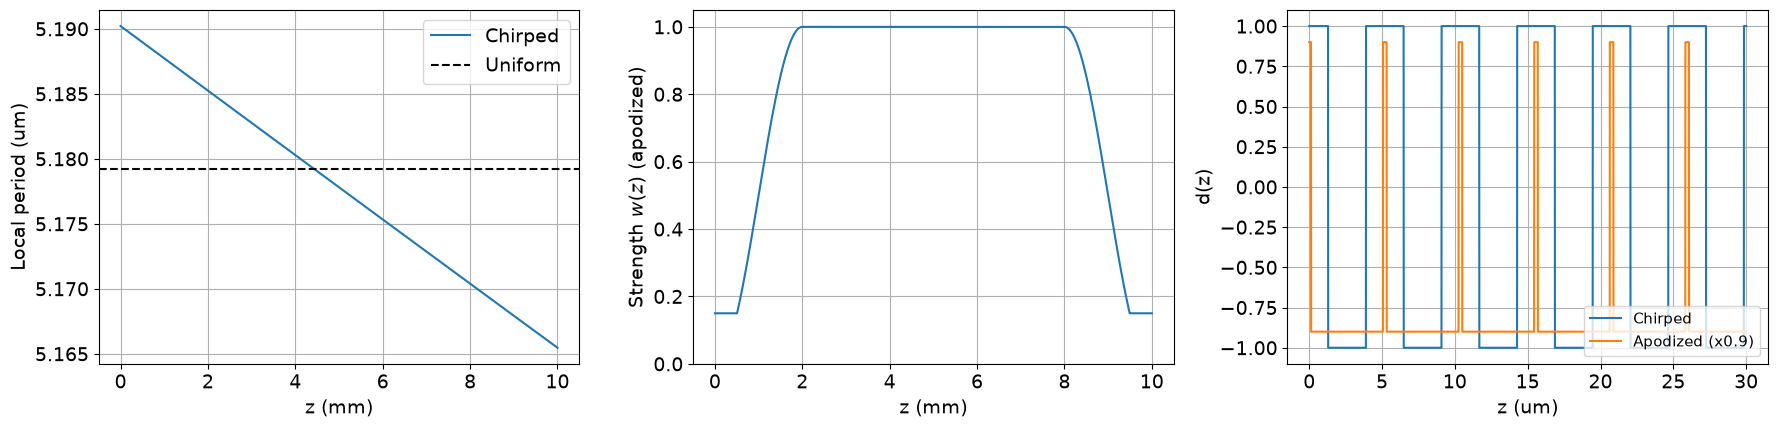

In [4]:
zplot = np.linspace(0, L, 2001)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.5), tight_layout=True)
ax1.plot(zplot/mm, 2*pi/(K1 + (K2 - K1)*zplot/L)/um, label='Chirped')
ax1.axhline(2*pi/Δk0/um, color='k', ls='--', label='Uniform')
ax1.set_xlabel('z (mm)'); ax1.set_ylabel('Local period (um)'); ax1.legend()

ax2.plot(zplot/mm, strength(zplot))
ax2.set_xlabel('z (mm)'); ax2.set_ylabel('Strength $w(z)$ (apodized)')
ax2.set_ylim(0, 1.05)

zz = np.linspace(0, 30*um, 3001)
ax3.plot(zz/um, chirped(zz), label='Chirped')
ax3.plot(zz/um, 0.9*apodized(zz), label='Apodized (x0.9)')
ax3.set_xlabel('z (um)'); ax3.set_ylabel('d(z)'); ax3.legend(loc='lower right', fontsize=11)
for ax in (ax1, ax2, ax3):
    ax.grid(True)

## Transfer functions

We compute $|H(\Delta k)|^2$ by integrating each $d(z)$ numerically on a 20 nm grid. Plotted against pump wavelength (with $\Delta k$ evaluated for SHG of that wavelength), it is each grating's CW phase-matching curve. This takes a few seconds.

Uniform grating peak / (2L/π)^2 = 1.000


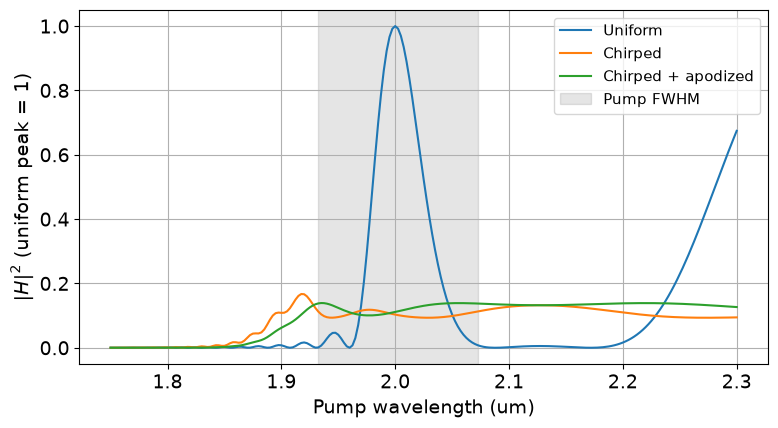

In [5]:
dz = 20*nm
zz = np.arange(0, L, dz) + dz/2

def H(poling, dk):
    d = poling(zz)
    return np.array([np.sum(d*np.exp(1j*k*zz))*dz for k in np.atleast_1d(dk)])

λs = np.linspace(1.75, 2.3, 221)*um
dk_λ = wg.beta(λs/2) - 2*wg.beta(λs)
H2 = {name: np.abs(H(g, dk_λ))**2 for name, g in gratings.items()}
H2max = H2['Uniform'].max()

fig, ax = plt.subplots(figsize=(8, 4.5), tight_layout=True)
for name in gratings:
    ax.plot(λs/um, H2[name]/H2max, label=name)
pump_band = 1/(1/λp + np.array([-1, 1])*Δν/2/c)
ax.axvspan(*np.sort(pump_band)/um, color='k', alpha=0.1, label='Pump FWHM')
ax.set_xlabel('Pump wavelength (um)'); ax.set_ylabel('$|H|^2$ (uniform peak = 1)')
ax.legend(fontsize=11); ax.grid(True)
print('Uniform grating peak / (2L/π)^2 = %0.3f' %(H2max/(2*L/pi)**2))

The uniform grating reaches the expected peak $(2L/\pi)^2$. The chirped gratings respond almost evenly across the whole pump band, at about 0.1-0.15 of that peak. A linear chirp converts each $\Delta k$ with an efficiency set by the chirp rate, so spreading the response over a wider band lowers it everywhere. The unapodized grating ripples near its band edge (the bump at 1.92 µm); the apodized one is smoother. Beyond 2.1 µm both stay high because $\Delta k(\lambda)$ is flat there.

## Simulation

Now the full simulation of each grating, with a weak pump. The uniform grating uses the `Kg` model. The others pass their poling function: `propagate` finds every domain wall, restarts the integrator there and, by default, limits the step to a quarter of the shortest domain.

**Step size.** The default limit is conservative for the apodized grating, whose shortest domains are a few hundred nm: it takes about 3.5 min. The accuracy is set by how far the nonlinear drive rotates within a step, about π over a full domain of the local period, so a step of 1/8 of the shortest period is enough. We pass that as `max_step`. Compared with the default, it changes the conversion by 0.6 %.

In [6]:
import time
λ_start, λ_stop = 800*nm, 3*um
f_max, f_min = c/λ_start, c/λ_stop
N = 2**10
Δt = 1/(f_max - f_min)
t = (np.arange(N) - N//2)*Δt
f_ref = (f_max + f_min)/2

frep = 250*MHz
pump = pulses.sech_pulse(t, τ, Pavg=0.1*uW, f_ref=f_ref, f0=c/λp, Npwr_dB=100, frep=frep, rng=1)
v_ref = 1/wg.beta1(λp/2)

outputs = {}
for name, g in gratings.items():
    t0 = time.time()
    if name == 'Uniform':
        out = wg.propagate(pump, v_ref=v_ref, Kg=Δk0).pulse
    else:
        wg.add_poling(g)
        out = wg.propagate(pump, v_ref=v_ref, max_step=2*pi/K2/8).pulse
    outputs[name] = out
    S = np.abs(out.A)**2
    conv = S[out.f_abs > 1.5*c/λp].sum()/np.sum(np.abs(pump.A)**2)
    print('%-20s SH conversion %0.2f %%  (%0.0f s)' %(name, 100*conv, time.time() - t0))

Uniform              SH conversion 2.73 %  (0 s)


Chirped              SH conversion 0.85 %  (32 s)


Chirped + apodized   SH conversion 0.93 %  (30 s)


## Comparison with the transfer function

The predicted SH spectrum is $|\Omega\,\mathcal{F}\{a^2\}\,H(\Delta k(\Omega))|^2$. We compute $\mathcal{F}\{a^2\}$ at the SH frequencies of the grid and scale all three predictions by one common factor, chosen so that the uniform grating's peak matches its simulation.

Uniform              spectral FWHM  5.6 THz, largest difference from the prediction: 4.8 % of its peak
Chirped              spectral FWHM 15.0 THz, largest difference from the prediction: 10.5 % of its peak
Chirped + apodized   spectral FWHM 18.8 THz, largest difference from the prediction: 8.0 % of its peak


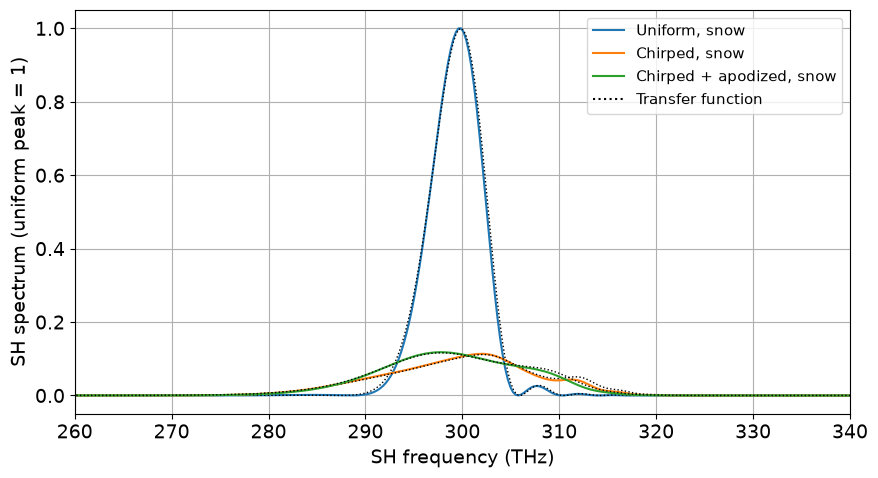

In [7]:
f_sh = pump.f_abs
band = (f_sh > 1.6*c/λp) & (f_sh < 2.4*c/λp)
fb = f_sh[band]
order = np.argsort(fb)
dk_sh = wg.beta(c/fb) - 2*wg.beta(2*c/fb)
#a^2 oscillates at 2 f_ref, so its component at absolute frequency f is ∫ a^2 exp(-i2π(f - 2f_ref)t) dt
a2 = np.exp(-2j*pi*np.outer(fb - 2*f_ref, t)) @ (pump.a**2) * pump.dt

pred = {name: np.abs(fb*a2*H(g, dk_sh))**2 for name, g in gratings.items()}
sim = {name: (np.abs(out.A)**2)[band] for name, out in outputs.items()}
scale = sim['Uniform'].max()/pred['Uniform'].max()

fig, ax = plt.subplots(figsize=(9, 5), tight_layout=True)
for (name, color) in zip(gratings, ['C0', 'C1', 'C2']):
    ax.plot(fb[order]/THz, sim[name][order]/sim['Uniform'].max(), color=color, label=name + ', snow')
    ax.plot(fb[order]/THz, scale*pred[name][order]/sim['Uniform'].max(), 'k:', lw=1)
    err = np.max(np.abs(sim[name] - scale*pred[name]))/sim[name].max()
    above = fb[sim[name] >= sim[name].max()/2]
    print('%-20s spectral FWHM %4.1f THz, largest difference from the prediction: %0.1f %% of its peak' %(name, (above.max() - above.min())/THz, 100*err))
ax.plot([], [], 'k:', label='Transfer function')
ax.set_xlim(260, 340)
ax.set_xlabel('SH frequency (THz)'); ax.set_ylabel('SH spectrum (uniform peak = 1)')
ax.legend(fontsize=11); ax.grid(True)

The simulations agree with the transfer-function prediction to within 5-11 % of each peak. The largest differences are at the high-frequency edge, near 310 THz, where the prediction's approximations are worst: it ignores the pump's GVD and uses the degenerate mismatch $\beta(\Omega) - 2\beta(\Omega/2)$ for pairs of pump frequencies that are far apart. The chirped gratings give an SH spectrum several times wider than the uniform grating (printed above), at about a third of the SH energy: that is the trade.

## Summary

- Any poling pattern can be given as a function `d(z)` with values ±1; `propagate` treats every domain wall exactly.
- Chirped gratings trade peak efficiency for bandwidth. The undepleted response is the grating's Fourier transform $H(\Delta k)$, which is cheap to compute and a good check of a design before simulating it.
- Duty-cycle apodization sets a local strength $\tfrac{2}{\pi}\sin(\pi D)$ and suppresses the ripple of abrupt grating ends.
- For gratings with very short domains, pass `max_step` (about 1/8 of the shortest period) instead of relying on the default, which can be several times slower.